In [64]:
import pandas as pd
import numpy as np
import cv2
import os
import random
import matplotlib.pyplot as plt

DATA LOAD

In [65]:
GERD= r"D:/AI BIOMEDICAL PROJECT/data/esophageal image/Endoscopy-esophagus"
CATAGORIES= ['esophagus','no-esophagus']

DATA PROCESSING

In [66]:
data=[]

for categories in CATAGORIES:
    pd=os.path.join(GERD,categories)
    label=CATAGORIES.index(categories)
    
    for img in os.listdir(pd):
        img=os.path.join(pd,img)
        img_arr=cv2.imread(img)
        img_arr= cv2.resize(img_arr,(100,100))
        data.append((img_arr,label))

In [67]:
data

[(array([[[15, 15, 15],
          [15, 15, 15],
          [15, 15, 15],
          ...,
          [15, 15, 15],
          [15, 15, 15],
          [15, 15, 15]],
  
         [[15, 15, 15],
          [15, 15, 15],
          [15, 15, 15],
          ...,
          [15, 15, 15],
          [15, 15, 15],
          [15, 15, 15]],
  
         [[15, 15, 15],
          [15, 15, 15],
          [15, 15, 15],
          ...,
          [15, 15, 15],
          [15, 15, 15],
          [15, 15, 15]],
  
         ...,
  
         [[15, 15, 15],
          [15, 15, 15],
          [15, 15, 15],
          ...,
          [15, 15, 15],
          [15, 15, 15],
          [15, 15, 15]],
  
         [[15, 15, 15],
          [15, 15, 15],
          [15, 15, 15],
          ...,
          [15, 15, 15],
          [15, 15, 15],
          [15, 15, 15]],
  
         [[15, 15, 15],
          [15, 15, 15],
          [15, 15, 15],
          ...,
          [15, 15, 15],
          [15, 15, 15],
          [15, 15, 15]]], dtype=u

In [68]:
random.shuffle(data)

In [69]:
x=[]
y=[]

for features,label in data:
    x.append(features)
    y.append(label)

In [70]:
x=np.array(x)
y=np.array(y)

In [71]:
x

array([[[[  3,   3,   3],
         [  1,   4,   2],
         [  3,   3,   3],
         ...,
         [  4,   4,   4],
         [  4,   4,   4],
         [  4,   4,   4]],

        [[  4,   4,   4],
         [  4,   5,   3],
         [  5,   5,   5],
         ...,
         [  4,   4,   4],
         [  2,   4,   4],
         [  3,   3,   3]],

        [[  5,   3,   2],
         [  3,   3,   3],
         [  1,   4,   2],
         ...,
         [  2,   4,   4],
         [  4,   4,   4],
         [  3,   3,   3]],

        ...,

        [[  2,   2,   2],
         [  0,   2,   2],
         [  2,   2,   2],
         ...,
         [  1,   1,   1],
         [  0,   2,   2],
         [  0,   1,   1]],

        [[  2,   2,   2],
         [  1,   1,   1],
         [  2,   2,   2],
         ...,
         [  1,   1,   1],
         [  0,   2,   2],
         [  2,   3,   3]],

        [[  2,   1,   3],
         [  3,   4,   2],
         [  3,   3,   3],
         ...,
         [  1,   1,   1],
        

In [72]:
x=x/255

In [73]:
x

array([[[[0.01176471, 0.01176471, 0.01176471],
         [0.00392157, 0.01568627, 0.00784314],
         [0.01176471, 0.01176471, 0.01176471],
         ...,
         [0.01568627, 0.01568627, 0.01568627],
         [0.01568627, 0.01568627, 0.01568627],
         [0.01568627, 0.01568627, 0.01568627]],

        [[0.01568627, 0.01568627, 0.01568627],
         [0.01568627, 0.01960784, 0.01176471],
         [0.01960784, 0.01960784, 0.01960784],
         ...,
         [0.01568627, 0.01568627, 0.01568627],
         [0.00784314, 0.01568627, 0.01568627],
         [0.01176471, 0.01176471, 0.01176471]],

        [[0.01960784, 0.01176471, 0.00784314],
         [0.01176471, 0.01176471, 0.01176471],
         [0.00392157, 0.01568627, 0.00784314],
         ...,
         [0.00784314, 0.01568627, 0.01568627],
         [0.01568627, 0.01568627, 0.01568627],
         [0.01176471, 0.01176471, 0.01176471]],

        ...,

        [[0.00784314, 0.00784314, 0.00784314],
         [0.        , 0.00784314, 0.00784314]

In [74]:
x.shape

(10662, 100, 100, 3)

In [75]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Flatten,Dense,Activation

In [76]:
model=Sequential()

#Convolutional layers
model.add(Conv2D(32,(3,3),input_shape=x.shape[1:],activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

#flatten layer
model.add(Flatten())

#Dense layers
model.add(Dense(256, activation='relu'))
model.add(Dense(128, activation='relu'))

#output layers
model.add(Dense(2,activation='softmax'))


In [77]:
# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


In [78]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])


In [79]:
history=model.fit(x, y, epochs=10, validation_split=0.1)


Epoch 1/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 45s 134ms/step - accuracy: 0.9120 - loss: 0.2062 - val_accuracy: 0.9381 - val_loss: 0.1679
Epoch 2/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 39s 129ms/step - accuracy: 0.9760 - loss: 0.0582 - val_accuracy: 0.9897 - val_loss: 0.0329
Epoch 3/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 38s 127ms/step - accuracy: 0.9870 - loss: 0.0354 - val_accuracy: 0.9766 - val_loss: 0.0530
Epoch 4/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 39s 128ms/step - accuracy: 0.9857 - loss: 0.0387 - val_accuracy: 0.9728 - val_loss: 0.0751
Epoch 5/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 38s 127ms/step - accuracy: 0.9847 - loss: 0.0410 - val_accuracy: 0.9963 - val_loss: 0.0069
Epoch 6/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 38s 126ms/step - accuracy: 0.9957 - loss: 0.0128 - val_accuracy: 0.9963 - val_loss: 0.0087
Epoch 7/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 42s 141ms/step - accuracy: 0.9955 - loss: 0.0134 - val_accuracy: 0.9953 - val_loss: 0.0129
Epoch 8/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 46s 152ms/step - accuracy: 0.9963 - loss: 0

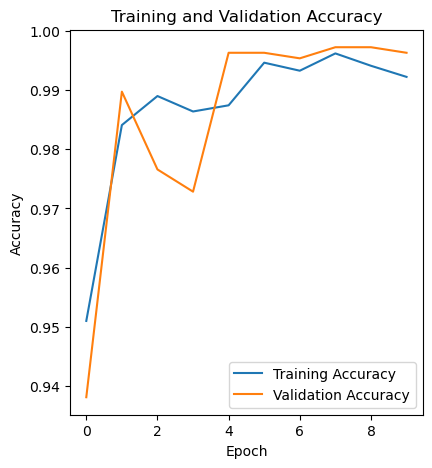

In [83]:
# Visualize training and validation accuracy over epochs
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


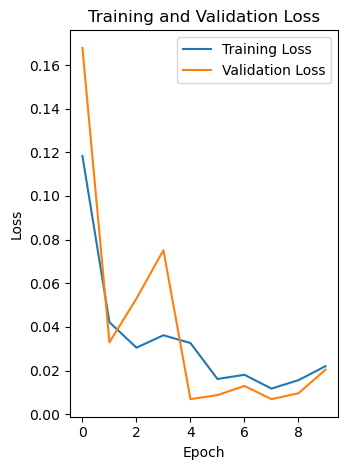

In [84]:
# Visualize training and validation loss over epochs
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [85]:
from keras.preprocessing import image
from tensorflow.keras.applications.vgg16 import preprocess_input


In [86]:
def predict_from_user_input(model):
    user_image_path = input("Enter the path of an image file: ")
    user_image_path = user_image_path.strip('\"')  # Remove double quotes

    img_pred = image.load_img(user_image_path, target_size=(100, 100))
    img_pred = image.img_to_array(img_pred)
    img_pred = np.expand_dims(img_pred, axis=0)

    rslt = model.predict(img_pred)

    print("Model Output:", rslt)

    if rslt[0][0] > rslt[0][1]:
        prediction = "GERD"
    else:
        prediction = "NO GERD"

    print("Prediction:", prediction)

In [87]:
# Call the function with your model
predict_from_user_input(model)

Enter the path of an image file: "C:\Users\HP\OneDrive\Desktop\00ab5b44-ff96-42fc-bc3b-9489fcc5d488.jpg"
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step
Model Output: [[1. 0.]]
Prediction: GERD


In [88]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Layer (type)                       ┃ Output Shape                  ┃     Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)                  │ (None, 98, 98, 32)            │         896 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ max_pooling2d_9 (MaxPooling2D)     │ (None, 49, 49, 32)            │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ conv2d_10 (Conv2D)                 │ (None, 47, 47, 64)            │      18,496 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ max_pooling2d_10 (MaxPooling2D)    │ (None, 23, 23, 64)            │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ conv2d_11 (Conv2D)                 │ (None, 21, 21, 128)           │      73,856 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ max_pooling2d_11 (MaxPooling2D)    │ (None, 10, 10, 128)           │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ flatten_3 (Flatten)                │ (None, 12800)                 │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dense_9 (Dense)                    │ (None, 256)                   │   3,277,056 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dense_10 (Dense)                   │ (None, 128)                   │      32,896 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dense_11 (Dense)                   │ (None, 2)                     │         258 │
└────────────────────────────────────┴───────────────────────────────┴─────────────┘

 Total params: 10,210,376 (38.95 MB)

 Trainable params: 3,403,458 (12.98 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,806,918 (25.97 MB)